# Spain power market: renewables, prices and battery value (2015–2018)

**Personal project.** Hourly Spanish electricity data (ENTSO-E and Red Eléctrica de España) with weather for five cities (OpenWeather), from the Kaggle dataset *Hourly energy demand generation and weather*.

**Business questions**
1. When is power cheap or expensive?
2. Do wind and solar push prices down, and what do they actually earn?
3. What could a battery earn from daily price differences?
4. How good are the grid operator's forecasts, and why is the final price above the day-ahead price?
5. How well can the day-ahead price be forecast with only the information available the day before?

All logic lives in `src/`; this notebook runs it and explains the results. Market questions use the **day-ahead price** (the wholesale auction). The dataset's *price actual* is the final price including system costs, analysed separately in section 4.

In [1]:
import sys, json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from clean import build_hourly
from analysis import (price_shape, renewables_vs_price, capture_prices,
                      battery_arbitrage, tso_forecast_accuracy, price_gap)
from forecast import run_forecast

DATA, CHARTS = ROOT / "data" / "raw", ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
pd.set_option("display.float_format", "{:,.2f}".format)

## 0. Data quality

The two sources do not line up cleanly, so every issue is counted before anything is fixed:
* timestamps mix CET (+01:00) and CEST (+02:00) offsets → converted to UTC, which gives a clean continuous hourly series;
* columns that are entirely empty or always zero are dropped;
* single-hour zeros for large plant types (e.g. nuclear) are treated as errors;
* gaps of up to 2 hours are interpolated; longer gaps are left empty and flagged, never invented;
* weather has exact duplicate city-hour rows and impossible readings (pressure of 0 or 1,008,371 hPa, wind of 133 m/s) → removed;
* the five cities are combined into one **population-weighted** national weather index rather than a plain average.

In [2]:
df, dq = build_hourly(DATA)
print(json.dumps(dq, indent=1, default=str))

{
 "energy_rows": 35064,
 "local_offsets": {
  "+02:00": 20664,
  "+01:00": 14400
 },
 "energy_missing_hours_utc": 0,
 "energy_duplicate_hours_utc": 0,
 "empty_columns": [
  "generation fossil coal-derived gas",
  "generation fossil oil shale",
  "generation fossil peat",
  "generation geothermal",
  "generation hydro pumped storage aggregated",
  "generation marine",
  "generation wind offshore",
  "forecast wind offshore eday ahead"
 ],
 "suspect_zero_values": {
  "generation nuclear": 3,
  "generation fossil gas": 1,
  "generation wind onshore": 3,
  "generation hydro water reservoir": 3
 },
 "energy_missing_values_before": {
  "generation biomass": 19,
  "generation fossil brown coal/lignite": 18,
  "generation fossil gas": 19,
  "generation fossil hard coal": 18,
  "generation fossil oil": 19,
  "generation hydro pumped storage consumption": 19,
  "generation hydro run-of-river and poundage": 19,
  "generation hydro water reservoir": 21,
  "generation nuclear": 20,
  "generation o

## 1. Price shape

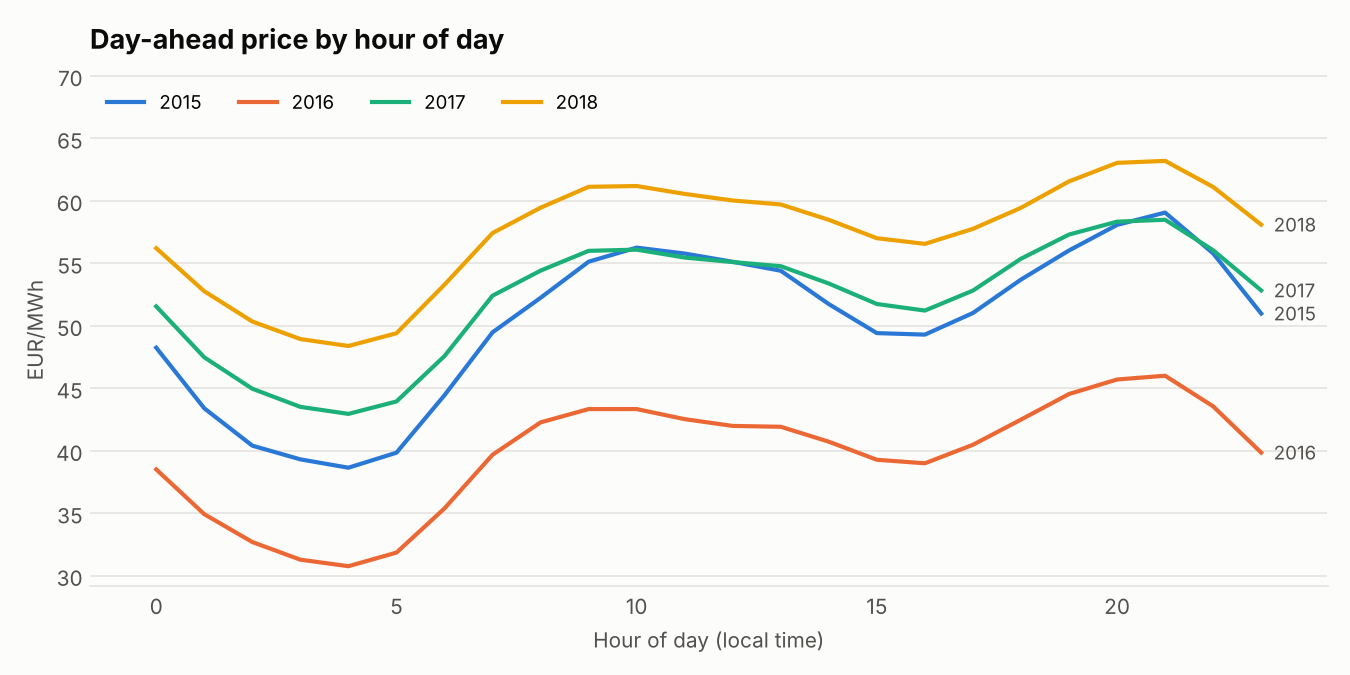

{'avg_price_by_year': {2015: 50.3, 2016: 39.7, 2017: 52.2, 2018: 57.3},
 'cheapest_hour': 4,
 'cheapest_hour_price': 40.2,
 'dearest_hour': 21,
 'dearest_hour_price': 56.7,
 'cheapest_month': 3,
 'dearest_month': 11}

In [3]:
q1 = price_shape(df, CHARTS)
display(Image(CHARTS / "01_price_by_hour.png"))
{k: v for k, v in q1.items() if k != "tables"}

Prices bottom out around 04:00 and peak around 21:00 every year. 2016 was much cheaper than the other years; 2018 was the most expensive.

## 2. Renewables vs price, and capture prices

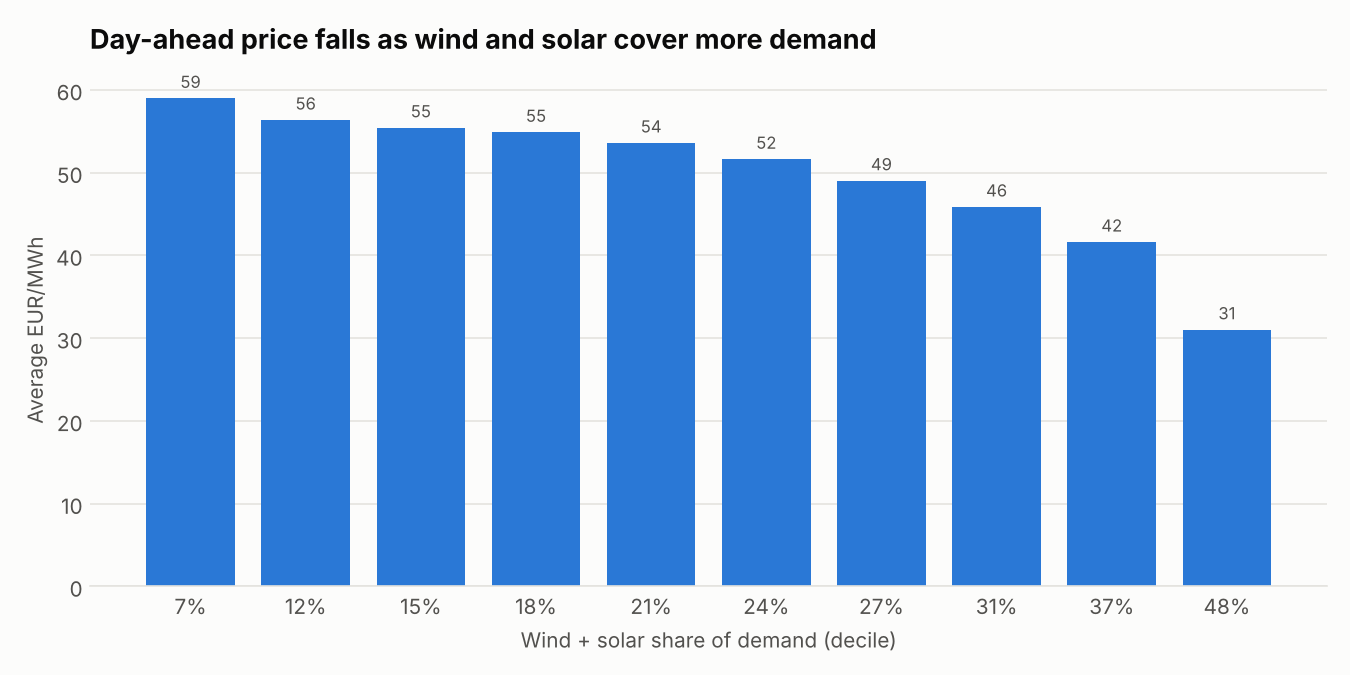

,vre_share,price,hours
vre_decile,,,
1,0.07,59.02,3506
2,0.12,56.40,3505
3,0.15,55.47,3505
4,0.18,54.92,3505
5,0.21,53.63,3506
6,0.24,51.66,3505
7,0.27,49.06,3505
8,0.32,45.89,3505
9,0.37,41.65,3505


{'correlation_vre_share_price': -0.56,
 'price_lowest_vre_decile': 59.0,
 'price_highest_vre_decile': 31.1,
 'vre_share_lowest_decile': 0.074,
 'vre_share_highest_decile': 0.476,
 'eur_per_mwh_per_10pp_vre_controlled': -6.32,
 'eur_per_mwh_per_gw_load_controlled': 1.13,
 'regression_r2': 0.708}

In [4]:
q2 = renewables_vs_price(df, CHARTS)
display(Image(CHARTS / "02_renewables_vs_price.png"))
display(q2["tables"]["price_by_vre_decile"])
{k: v for k, v in q2.items() if k != "tables"}

The raw relationship is strong, but windy hours also differ in demand, hour and season. The regression holds demand, hour, month and year constant: each extra 10 percentage points of wind and solar share is still associated with a clearly lower day-ahead price. Fuel and carbon prices are not in the dataset, so this is an association, not a full causal model.

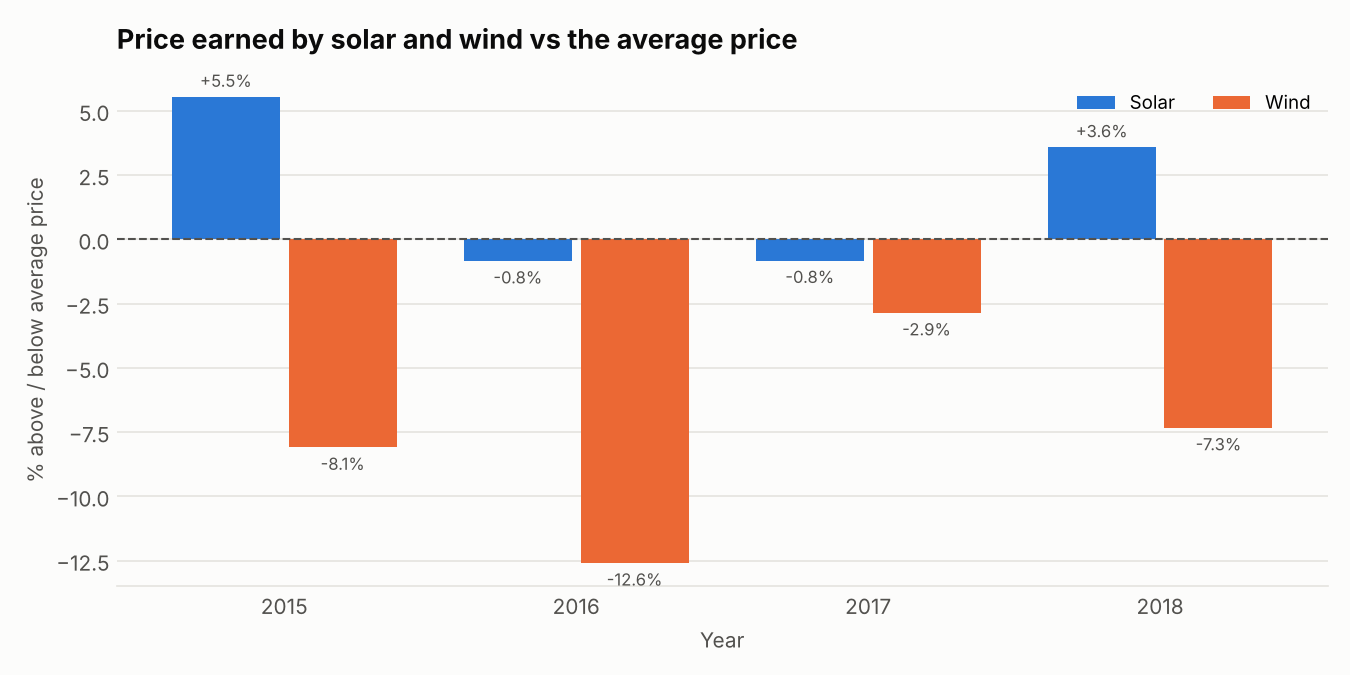

,baseload,solar_capture,solar_capture_rate,wind_capture,wind_capture_rate
year,,,,,
2015,50.33,53.11,1.05,46.25,0.92
2016,39.67,39.33,0.99,34.67,0.87
2017,52.24,51.81,0.99,50.74,0.97
2018,57.29,59.34,1.04,53.09,0.93


In [5]:
q2b = capture_prices(df, CHARTS)
display(Image(CHARTS / "03_capture_rates.png"))
q2b["tables"]["capture_prices"]

**Capture price** = the generation-weighted price a technology earns; the **capture rate** divides it by the average price. Wind earns below average every year (it blows hardest when it is pushing prices down). Solar earned close to or above average in this period, because Spain had little solar at the time and it produced during daytime demand. That is the reverse of the situation in more recent years, as solar capacity has grown.

## 3. Battery arbitrage

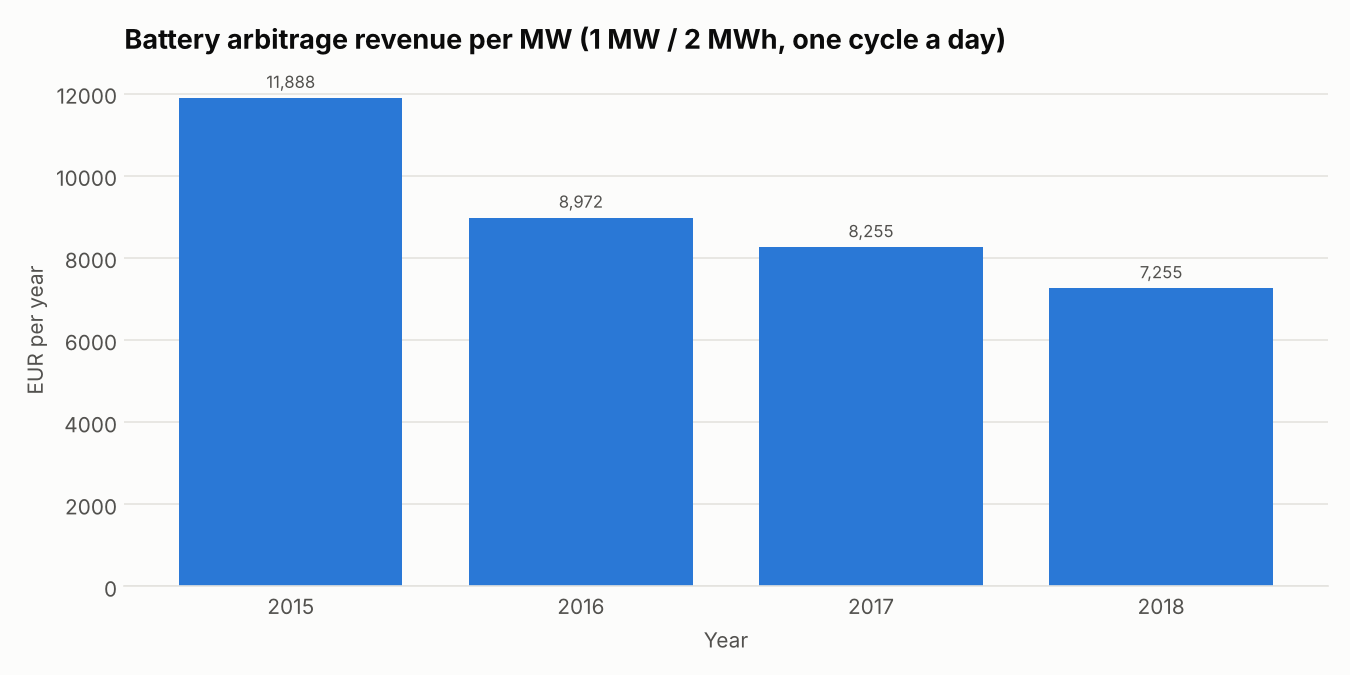

{'assumptions': {'power_mw': 1.0,
  'energy_mwh': 2.0,
  'round_trip_efficiency': 0.88,
  'cycles_per_day': 1},
 'revenue_per_mw_by_year': {2015: 11888.0,
  2016: 8972.0,
  2017: 8255.0,
  2018: 7255.0},
 'avg_daily_spread_eur': 20.5,
 'best_month_avg': 1,
 'worst_month_avg': 6,
 'share_days_not_worth_cycling': 0.055}

In [6]:
q3 = battery_arbitrage(df, CHARTS)
display(Image(CHARTS / "04_battery_revenue.png"))
{k: v for k, v in q3.items() if k != "tables"}

A 1 MW / 2 MWh battery doing one cycle a day (88% round-trip efficiency, charge before discharge). All 24 day-ahead prices are published together the day before, so picking the best hours within a day is realistic for this market. Revenue from daily price differences alone is modest and fell each year as the daily spread narrowed; real projects stack other income such as grid services.

## 4. Grid operator forecasts and the price gap

In [7]:
q4 = tso_forecast_accuracy(df)
q4

{'load_wape': 0.011,
 'solar_wape': 0.0848,
 'wind_wape': 0.0333,
 'wind_forecast_correlation': 0.9947}

Error is measured as total absolute error ÷ total actual (WAPE), which avoids division by near-zero solar output at night. The **wind forecast is unusually accurate** (correlation ≈ 0.99). That is suspicious for a true day-ahead forecast and suggests it may have been updated closer to real time, so section 5 also shows results without it.

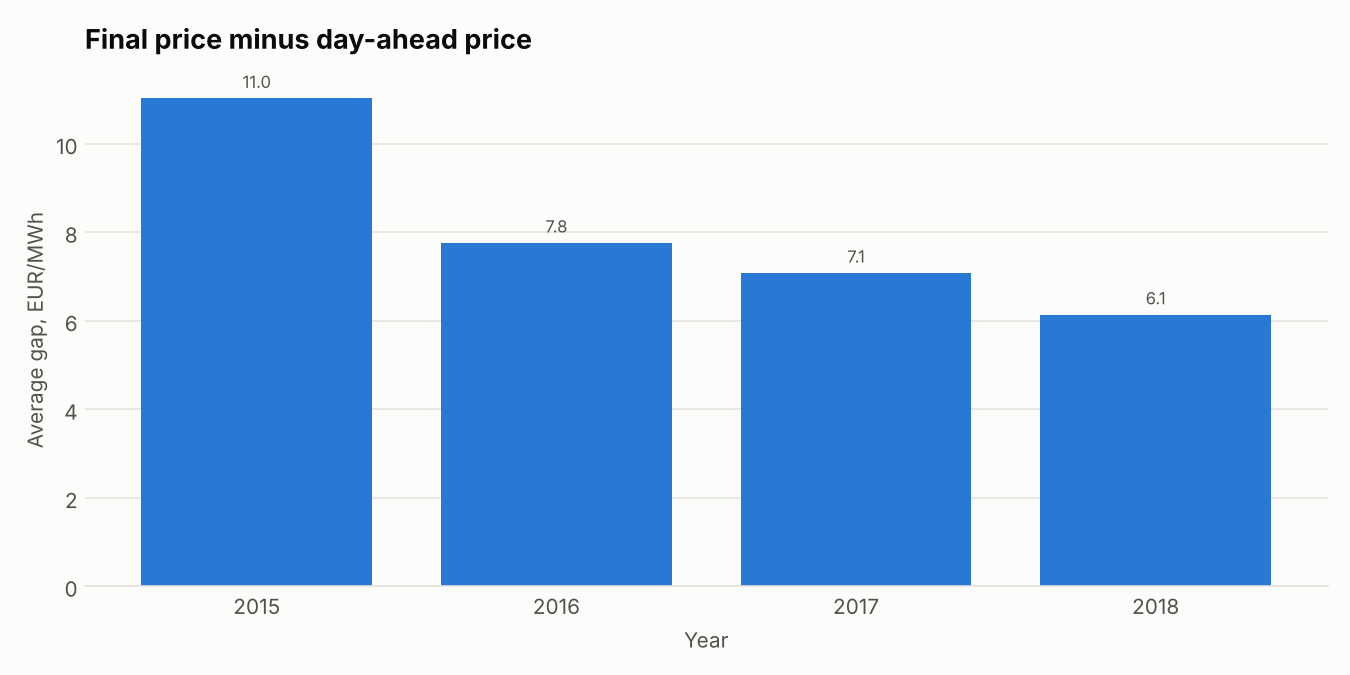

{'avg_gap_by_year': {2015: 11.04, 2016: 7.77, 2017: 7.09, 2018: 6.15},
 'share_hours_final_above_day_ahead': 0.888,
 'avg_gap_all': 8.01}

In [8]:
q4b = price_gap(df, CHARTS)
display(Image(CHARTS / "05_price_gap.png"))
q4b

The final price sits above the day-ahead price in almost nine hours out of ten, because it adds system costs on top of the auction price. This gap is structural, not a trading opportunity, which is why the market analyses use the day-ahead price.

## 5. Day-ahead price forecast

The auction closes at 12:00 the day before delivery, so the model only uses: day-ahead prices already published, the morning of the previous day's system data, the operator's published forecasts for the target day, and the calendar. It never uses the previous hour's actual price.

* **Model choice:** ridge regression vs gradient boosting, predicting either the price or the price relative to yesterday's average, compared on 2017 only.
* **Test:** the chosen set-up is run once on 2018, retrained at the start of every month on all earlier data (walk-forward).

,mae,rmse,bias
model,,,
ridge | level,5.23,7.16,1.51
ridge | relative_to_yesterday,5.23,7.16,1.51
gradient_boosting | level,5.50,8.25,2.12
gradient_boosting | relative_to_yesterday,4.99,7.05,1.78
naive_same_hour_yesterday,7.30,10.84,-0.12
naive_same_hour_last_week,10.51,14.21,-0.34


,mae,rmse,bias,rmae_vs_naive_d1
model,,,,
"gradient_boosting | relative_to_yesterday (chosen, retrained monthly)",5.38,6.85,2.70,0.77
gradient_boosting | relative_to_yesterday trained once on 2015-2017,6.79,8.33,4.61,0.97
gradient_boosting | relative_to_yesterday without wind/solar forecasts,6.62,8.75,2.53,0.94
naive_same_hour_yesterday,7.02,10.45,0.12,1.00
naive_same_hour_last_week,11.18,15.95,0.43,1.59


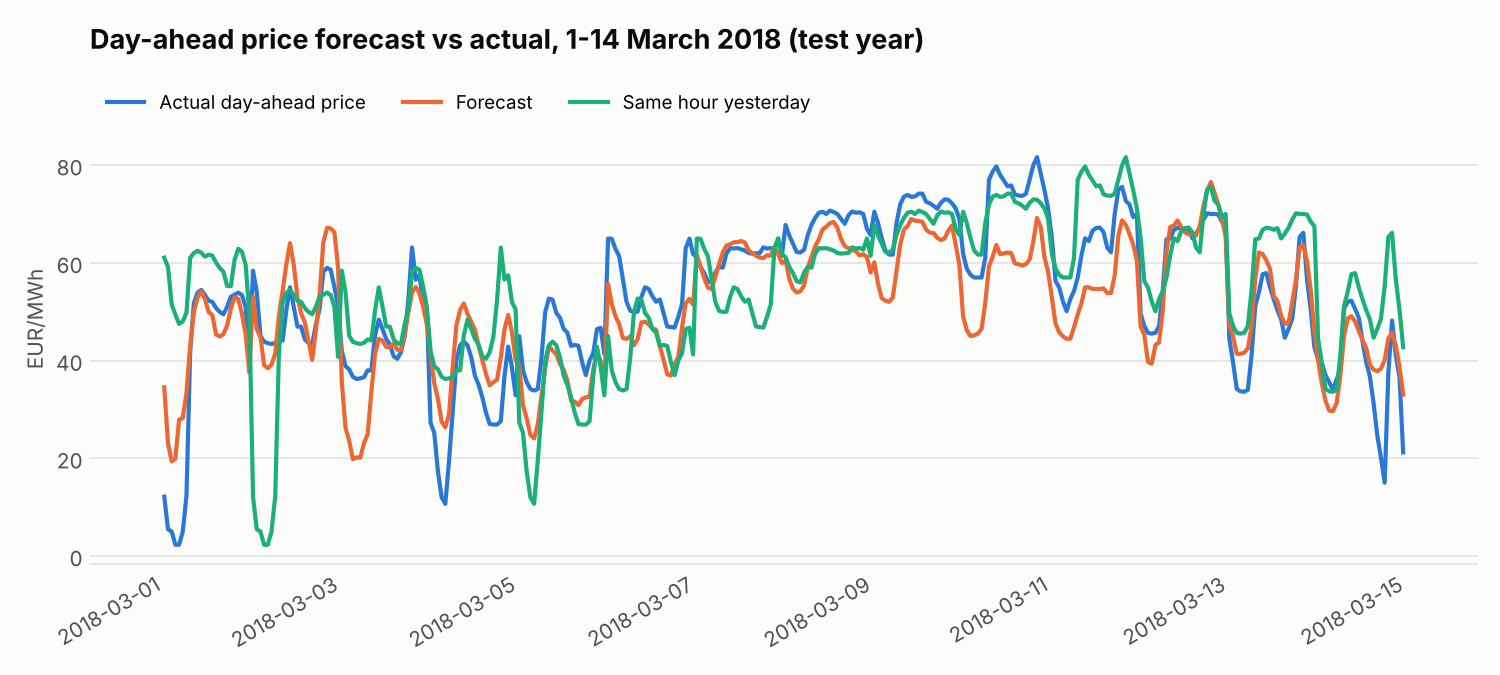

{'chosen_setup': 'gradient_boosting | relative_to_yesterday',
 'validation_period': '2017 (walk-forward, monthly retrain)',
 'test_period': '2018 (walk-forward, monthly retrain)',
 'test_rows': 8760,
 'test_mae': 5.376,
 'test_rmse': 6.854,
 'naive_d1_mae': 7.023,
 'improvement_vs_naive_d1': 0.235,
 'trained_once_mae': 6.795,
 'trained_once_bias': 4.607,
 'without_wind_solar_fc_mae': 6.623,
 'top_drivers': {'residual_load_fc': 4.518,
  'da_mean_d1': 0.381,
  'hydro_reservoir_am_d1': 0.318,
  'nuclear_am_d1': 0.198,
  'da_max_d1': 0.168}}

In [9]:
q5 = run_forecast(df, CHARTS)
display(q5["tables"]["forecast_validation_2017"])
display(q5["tables"]["forecast_test_2018"])
display(Image(CHARTS / "06_forecast_vs_actual.png"))
{k: v for k, v in q5.items() if k != "tables"}

In [10]:
q5["tables"]["forecast_trained_once_bias_by_month_2018"].T

month,1,2,3,4,5,6,7,8,9,10,11,12
bias_eur,2.16,3.20,3.56,1.10,5.20,4.40,3.45,5.35,6.89,8.55,5.47,5.79


A model trained once on 2015–2017 under-forecasts every month of 2018 (positive bias = actual above forecast), because fuel and carbon costs rose and they are not in the dataset. Retraining monthly removes most of that drift. The forecast leans heavily on the operator's residual-load forecast (demand minus expected wind and solar); without the wind and solar forecasts the gain over the naive baseline shrinks a lot, so that dependency is the main caveat.

## Limitations
* 2015–2018 data: little solar on the system, so solar results do not describe today's market.
* No fuel or carbon prices, which drive much of the price level.
* The battery model is simple: one cycle a day, perfect knowledge of the day's auction prices, no degradation or grid-service revenue.
* The wind forecast field may not be a true day-ahead forecast (see section 4).